## 1、为什么需要切分

获取Document对象后，需要将其切分成一个个小块（chunk）。之所以需要进行切分时出于以下考虑：
- **长文档问题**：大模型存在最大输入的token限制，如果一个Document非常大，在输入大模型时会被截断，导致信息缺失。
- **检索精度**：Document可能包含非常多无关的信息，这些无效信息会干扰大模型的生成，而小块检索更精准。
- **成本控制**：减少不必要的token消耗。

无论是在存储还是检索过程中，都以这些chunk为基本单位，这样能有效的避免内容噪声干扰和超出最大token的问题。

## 2、Chunking拆分的策略

- 根据句子拆分：这种方法按照自然句子边界进行切分，以保持语义完整性。
- 按照固定字符数来切分：这种策略根据特定的字符数量来划分文本，但可能会在不适当的位置切断句子。
- 按固定字符数来切分，结合重叠窗口（overlapping windows）：此方法与按字符数切分相似，但通过重叠窗口技术避免切分关键内容，确保信息连贯性。
- 递归字符切分方法：通过递归字符方式动态确定切分点，这种方法可以根据文档的复杂性和内容密度来调整块的大小。
- 根据语义内容切分：这种高级策略依据文本的语义内容来划分块，旨在保持相关信息的集中和完整，适用于需要高度语义保持的应用场景。

第2种方法和第3种方法主要基于字符进行文本的切分，而不考虑文章的实际内容和语义，虽然简单，但可能会导致主题或语义上的断裂。

相对而言，第4种递归方法更加灵活和高效，它结合了固定长度切分和语义分析。通常是首选策略，因为它能够更好的确保每个段落包含一个完整的主题。

而第5种方法，基于语义的分割虽然能精确的切分出完整的主题段落，但这种方法效率较低。它需要运行复杂的分段算法（segmentation algorithm），处理速度较慢，并且段落长度可能极不均匀。因此，尽管它在某些需要高精度语义保持的场景下有其应用价值，但并不适合所有情况。

这些方法各有优势和局限，选择适当的分块策略取决于具体的应用需求和预期的检索效果。

## 3、TextSplitter源码分析

```python
class TextSplitter(BaseDocumentTransformer, ABC):
    """Interface for splitting text into chunks."""

    def __init__(
        self,
        chunk_size: int = 4000,
        chunk_overlap: int = 200,
        length_function: Callable[[str], int] = len,
        keep_separator: bool | Literal["start", "end"] = False,  # noqa: FBT001,FBT002
        add_start_index: bool = False,  # noqa: FBT001,FBT002
        strip_whitespace: bool = True,  # noqa: FBT001,FBT002
    ) -> None:
        """Create a new `TextSplitter`.

        Args:
            chunk_size: Maximum size of chunks to return
            chunk_overlap: Overlap in characters between chunks
            length_function: Function that measures the length of given chunks
            keep_separator: Whether to keep the separator and where to place it
                in each corresponding chunk `(True='start')`
            add_start_index: If `True`, includes chunk's start index in metadata
            strip_whitespace: If `True`, strips whitespace from the start and end of
                every document

        Raises:
            ValueError: If `chunk_size` is less than or equal to 0
            ValueError: If `chunk_overlap` is less than 0
            ValueError: If `chunk_overlap` is greater than `chunk_size`
        """
        if chunk_size <= 0:
            msg = f"chunk_size must be > 0, got {chunk_size}"
            raise ValueError(msg)
        if chunk_overlap < 0:
            msg = f"chunk_overlap must be >= 0, got {chunk_overlap}"
            raise ValueError(msg)
        if chunk_overlap > chunk_size:
            msg = (
                f"Got a larger chunk overlap ({chunk_overlap}) than chunk size "
                f"({chunk_size}), should be smaller."
            )
            raise ValueError(msg)
        self._chunk_size = chunk_size
        self._chunk_overlap = chunk_overlap
        self._length_function = length_function
        self._keep_separator = keep_separator
        self._add_start_index = add_start_index
        self._strip_whitespace = strip_whitespace

    @abstractmethod
    def split_text(self, text: str) -> list[str]:
        """Split text into multiple components.

        Args:
            text: The text to split.

        Returns:
            A list of text chunks.
        """

    def create_documents(
        self, texts: list[str], metadatas: list[dict[Any, Any]] | None = None
    ) -> list[Document]:
        """Create a list of `Document` objects from a list of texts.

        Args:
            texts: A list of texts to be split and converted into documents.
            metadatas: Optional list of metadata to associate with each document.

        Returns:
            A list of `Document` objects.
        """
        metadatas_ = metadatas or [{}] * len(texts)
        documents = []
        for i, text in enumerate(texts):
            index = 0
            previous_chunk_len = 0
            for chunk in self.split_text(text):
                metadata = copy.deepcopy(metadatas_[i])
                if self._add_start_index:
                    offset = index + previous_chunk_len - self._chunk_overlap
                    index = text.find(chunk, max(0, offset))
                    metadata["start_index"] = index
                    previous_chunk_len = len(chunk)
                new_doc = Document(page_content=chunk, metadata=metadata)
                documents.append(new_doc)
        return documents

    def split_documents(self, documents: Iterable[Document]) -> list[Document]:
        """Split documents.

        Args:
            documents: The documents to split.

        Returns:
            A list of split documents.
        """
        texts, metadatas = [], []
        for doc in documents:
            texts.append(doc.page_content)
            metadatas.append(doc.metadata)
        return self.create_documents(texts, metadatas=metadatas)

    def _join_docs(self, docs: list[str], separator: str) -> str | None:
        text = separator.join(docs)
        if self._strip_whitespace:
            text = text.strip()
        return text or None

    def _merge_splits(self, splits: Iterable[str], separator: str) -> list[str]:
        # We now want to combine these smaller pieces into medium size
        # chunks to send to the LLM.
        separator_len = self._length_function(separator)

        docs = []
        current_doc: list[str] = []
        total = 0
        for d in splits:
            len_ = self._length_function(d)
            if (
                total + len_ + (separator_len if len(current_doc) > 0 else 0)
                > self._chunk_size
            ):
                if total > self._chunk_size:
                    logger.warning(
                        "Created a chunk of size %d, which is longer than the "
                        "specified %d",
                        total,
                        self._chunk_size,
                    )
                if len(current_doc) > 0:
                    doc = self._join_docs(current_doc, separator)
                    if doc is not None:
                        docs.append(doc)
                    # Keep on popping if:
                    # - we have a larger chunk than in the chunk overlap
                    # - or if we still have any chunks and the length is long
                    while total > self._chunk_overlap or (
                        total + len_ + (separator_len if len(current_doc) > 0 else 0)
                        > self._chunk_size
                        and total > 0
                    ):
                        total -= self._length_function(current_doc[0]) + (
                            separator_len if len(current_doc) > 1 else 0
                        )
                        current_doc = current_doc[1:]
            current_doc.append(d)
            total += len_ + (separator_len if len(current_doc) > 1 else 0)
        doc = self._join_docs(current_doc, separator)
        if doc is not None:
            docs.append(doc)
        return docs

    @classmethod
    def from_huggingface_tokenizer(
        cls, tokenizer: PreTrainedTokenizerBase, **kwargs: Any
    ) -> TextSplitter:
        """Text splitter that uses Hugging Face tokenizer to count length.

        Args:
            tokenizer: The Hugging Face tokenizer to use.

        Returns:
            An instance of `TextSplitter` using the Hugging Face tokenizer for length
                calculation.
        """
        if not _HAS_TRANSFORMERS:
            msg = (
                "Could not import transformers python package. "
                "Please install it with `pip install transformers`."
            )
            raise ValueError(msg)

        if not isinstance(tokenizer, PreTrainedTokenizerBase):
            msg = "Tokenizer received was not an instance of PreTrainedTokenizerBase"  # type: ignore[unreachable]
            raise ValueError(msg)  # noqa: TRY004

        def _huggingface_tokenizer_length(text: str) -> int:
            return len(tokenizer.tokenize(text))

        return cls(length_function=_huggingface_tokenizer_length, **kwargs)

    @classmethod
    def from_tiktoken_encoder(
        cls,
        encoding_name: str = "gpt2",
        model_name: str | None = None,
        allowed_special: Literal["all"] | AbstractSet[str] = set(),
        disallowed_special: Literal["all"] | Collection[str] = "all",
        **kwargs: Any,
    ) -> Self:
        """Text splitter that uses `tiktoken` encoder to count length.

        Args:
            encoding_name: The name of the tiktoken encoding to use.
            model_name: The name of the model to use.

                If provided, this will override the `encoding_name`.
            allowed_special: Special tokens that are allowed during encoding.
            disallowed_special: Special tokens that are disallowed during encoding.

        Returns:
            An instance of `TextSplitter` using tiktoken for length calculation.

        Raises:
            ImportError: If the tiktoken package is not installed.
        """
        if not _HAS_TIKTOKEN:
            msg = (
                "Could not import tiktoken python package. "
                "This is needed in order to calculate max_tokens_for_prompt. "
                "Please install it with `pip install tiktoken`."
            )
            raise ImportError(msg)

        if model_name is not None:
            enc = tiktoken.encoding_for_model(model_name)
        else:
            enc = tiktoken.get_encoding(encoding_name)

        def _tiktoken_encoder(text: str) -> int:
            return len(
                enc.encode(
                    text,
                    allowed_special=allowed_special,
                    disallowed_special=disallowed_special,
                )
            )

        if issubclass(cls, TokenTextSplitter):
            extra_kwargs = {
                "encoding_name": encoding_name,
                "model_name": model_name,
                "allowed_special": allowed_special,
                "disallowed_special": disallowed_special,
            }
            kwargs = {**kwargs, **extra_kwargs}

        return cls(length_function=_tiktoken_encoder, **kwargs)

    @override
    def transform_documents(
        self, documents: Sequence[Document], **kwargs: Any
    ) -> Sequence[Document]:
        """Transform sequence of documents by splitting them.

        Args:
            documents: The sequence of documents to split.

        Returns:
            A list of split documents.
        """
        return self.split_documents(list(documents))
```
几个常用的文档切分器的方法的调用
```
# 方式1：传入的参数类型：str；返回值类型：list[str]
split_text(text)
# 用法：传入单个字符串，切分成多个字符串块
# 调用关系：抽象方法，由子类实现具体切分逻辑

# 方式2：传入的参数类型：list[str]；返回值类型：list[Document]
create_documents(texts, metadatas=None)
# 用法：传入字符串列表，将每个字符串切分后封装成 Document
# 调用关系：底层遍历 texts，并对每个 text 调用 split_text(text)

# 方式3：传入的参数类型：Iterable[Document]；返回值类型：list[Document]
split_documents(documents)
# 用法：传入 Document 集合，取出 page_content 和 metadata 后重新切分成 Document
# 调用关系：底层调用 create_documents(texts, metadatas=metadatas)，再间接调用split_text(text)

# 总调用链
split_documents(documents)
    -> create_documents(texts, metadatas=metadatas)
        -> split_text(text)
```
此外，这里提供了一个可视化展示文本如何分割的工具，https://chunkviz.up.railway.app/

## 4、具体实现

LangChain提供了许多不同类型的文档切分器，官网地址：https://python.langchain.com/api_reference/text_splitters/index.html

### 4.1 CharacterTextSplitter：Split by character

参数说明：
- chunk_size：每个切块的最大字符数量，默认值为4000.
- chunk_overlap：相邻两个切块之间的最大重叠字符数量，默认值为200。为了保证段之间语义完整，可以设置每个块之间有一部分重叠。
- separator：分割使用的分隔符，默认值为"\n\n"。
- length_function：用于计算切块长度的方法，默认赋值为父类TextSplitter的len函数。

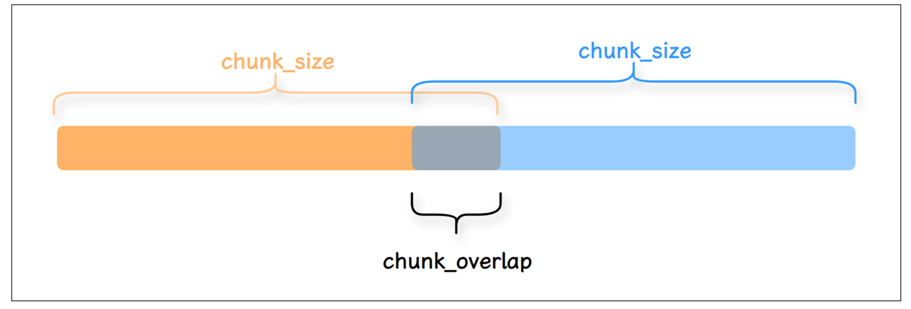

举例1:字符串文本的分割

In [1]:
# 1.导入相关依赖
from langchain_text_splitters import CharacterTextSplitter
from openai import api_key

# 2.示例文本
text = """
LangChain 是一个用于开发由语言模型驱动的应用程序的框架的。它提供了一套工具和抽象，使开发者能够更容易地构建复杂的应用程序。
"""

splitter = CharacterTextSplitter(
    chunk_size=50,
    chunk_overlap=5,
    separator="" # 设置为空字符串时，表示禁用分隔符优先
)

texts = splitter.split_text(text)

for i, chunk in enumerate(texts):
    print(f"块 {i+1}:长度：{len(chunk)}")
    print(chunk)
    print("-" * 50)

块 1:长度：49
LangChain 是一个用于开发由语言模型驱动的应用程序的框架的。它提供了一套工具和抽象，使开发
--------------------------------------------------
块 2:长度：22
象，使开发者能够更容易地构建复杂的应用程序。
--------------------------------------------------


说明：若必须禁用分隔符（如处理无空格文本），需容忍实际块长略小于 chunk_size （尤其对中文）

举例2:指定分隔符

In [2]:
# 1.导入相关依赖
from langchain_text_splitters import CharacterTextSplitter

# 2.定义要分割的文本
text = "这是一个示例文本啊。我们将使用CharacterTextSplitter将其分割成小块。分割基于字符数。"

splitter = CharacterTextSplitter(
    chunk_size=30,
    chunk_overlap=5,
    separator="。" # 设置为空字符串时，表示禁用分隔符优先
)

texts = splitter.split_text(text)

for i, chunk in enumerate(texts):
    print(f"块 {i+1}:长度：{len(chunk)}")
    print(chunk)
    print("-" * 50)

Created a chunk of size 33, which is longer than the specified 30


块 1:长度：9
这是一个示例文本啊
--------------------------------------------------
块 2:长度：33
我们将使用CharacterTextSplitter将其分割成小块
--------------------------------------------------
块 3:长度：7
分割基于字符数
--------------------------------------------------


注意：无重叠。

separator优先原则：当设置了 separator （如"。"），分割器会首先尝试在分隔符处分割，然后再考虑 chunk_size。这是为了避免在句子中间硬性切断。这种设计是为了：
1. 优先保持语义完整性（不切断句子）
2. 避免产生无意义的碎片（如半个单词/不完整句子）
3. 如果 chunk_size 比片段小，无法拆分片段，导致 overlap失效。
4. chunk_overlap仅在合并后的片段之间生效（如果 chunk_size 足够大）。如果没有合并的片段，则 overlap失效。

举例3:指定分割符

In [3]:
# 1.导入相关依赖
from langchain_text_splitters import CharacterTextSplitter

# 2.定义要分割的文本
text = "这是第一段文本。这是第二段内容。最后一段结束。"

splitter = CharacterTextSplitter(
    separator="。",
    chunk_size=20,
    chunk_overlap=8,
    keep_separator=True  # chunk中是否保留切割符
)

texts = splitter.split_text(text)
for i, chunk in enumerate(texts):
    print(f"块 {i+1}:长度：{len(chunk)}")
    print(chunk)
    print("-" * 50)

块 1:长度：15
这是第一段文本。这是第二段内容
--------------------------------------------------
块 2:长度：16
。这是第二段内容。最后一段结束。
--------------------------------------------------


注意：有重叠。此时，文本“这是第二段内容。”的token正好就是8。

### 4.2 RecursiveCharacterTextSplitter：最常用

文档切分器中比较常用的是`RecursiveCharacterTextSplitter（递归字符文本切分器）`，遇到特定字符时进行分割。默认情况下，它尝试切割的字符包括["\n\n", "\n", " ", ""]。

RecursiveCharacterTextSplitter代表了一类很典型的RAG切分思路。

优先按照自然的文本边界切分（使用切割的字符），若切分后的片段仍过大，再逐级退化到更细粒度的分割符，以此类推。最后再按chunk_size和chunk_overlap组织为最终chunk。

它的价值在于：尽量保留语义完整性，同时把片段控制在embedding与检索更友好的长度范围内。

此外，还可以自定义的方式添加", 。"等分割字符。

特点：
- **保留上下文**：优先在自然语言边界（如段落、句子结尾）处分割，减少信息碎片化。
- **智能分段**：通过递归尝试多种分割符，将文本分割为大小接近chunk_size的片段。
- **灵活适配**：适用于多种文本类型（代码、Markdown、普通文本等），是LangChain中最通用的文本拆分器。

可以指定的参数包括：
- chunk_size ：同TextSplitter（父类） 。
- chunk_overlap ：同TextSplitter（父类） 。
- length_function ：同TextSplitter（父类） 。
- add_start_index ：同TextSplitter（父类） 。

举例1：使用split_text()方法演示

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=10,
    chunk_overlap=0,
    add_start_index=True
)

text="LangChain框架特性\n\n多模型集成(GPT/Claude)\n记忆管理功能\n链式调用设计。文档分析场景示例：需要处理PDF/Word等格式。"

texts = splitter.split_text(text)
for i, chunk in enumerate(texts):
    print(f"块{i + 1},长度：{len(chunk)}")
    print(chunk)
    print('-' * 50)

块1,长度：10
LangChain框
--------------------------------------------------
块2,长度：3
架特性
--------------------------------------------------
块3,长度：9
多模型集成(GPT
--------------------------------------------------
块4,长度：8
/Claude)
--------------------------------------------------
块5,长度：6
记忆管理功能
--------------------------------------------------
块6,长度：9
链式调用设计。文档
--------------------------------------------------
块7,长度：10
分析场景示例：需要处
--------------------------------------------------
块8,长度：10
理PDF/Word等
--------------------------------------------------
块9,长度：3
格式。
--------------------------------------------------


举例2：使用create_documents()方法演示，传入字符串列表，返回Document对象列表

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=10,
    chunk_overlap=0,
    add_start_index=True
)

list=["LangChain框架特性\n\n多模型集成(GPT/Claude)\n记忆管理功能\n链式调用设计。文档分析场景示例：需要处理PDF/Word等格式。"]

docs = splitter.create_documents(list)
for doc in docs:
    print(doc)
    print('-' * 50)

page_content='LangChain框' metadata={'start_index': 0}
--------------------------------------------------
page_content='架特性' metadata={'start_index': 10}
--------------------------------------------------
page_content='多模型集成(GPT' metadata={'start_index': 15}
--------------------------------------------------
page_content='/Claude)' metadata={'start_index': 24}
--------------------------------------------------
page_content='记忆管理功能' metadata={'start_index': 33}
--------------------------------------------------
page_content='链式调用设计。文档' metadata={'start_index': 40}
--------------------------------------------------
page_content='分析场景示例：需要处' metadata={'start_index': 49}
--------------------------------------------------
page_content='理PDF/Word等' metadata={'start_index': 59}
--------------------------------------------------
page_content='格式。' metadata={'start_index': 69}
--------------------------------------------------


逐步分割过程

第一阶段：顶级分割（按\n\n）

1、首次分割
```
text.split("\n\n") →
[
    "LangChain框架特性",
    "多模型集成(GPT/Claude)\n记忆管理功能\n链式调用设计。文档分析场景示例：需要处理PDF/Word等格式。"
]
```

   - 第一部分长度：13字符 > 10 → 需要继续分割
   - 第二部分长度：79字符 > 10 → 需要继续分割

第二阶段：递归分割第一部分 “LangChain框架特性”

1、尝试\n：无匹配。

2、尝试 空格：无匹配

3、回退到"" 字符级分割
```
list("LangChain框架特性") →
['L','a','n','g','C','h','a','i','n','框','架','特','性']
```
   - 前10字符： "LangChain框"
   - 剩余部分： "架特性"

第三阶段：递归分割第二部分（长段落）

1、按\n分割
```
"多模型集成(GPT/Claude)\n记忆管理功能\n链式调用设计。文档...".split("\n") →
[
    "多模型集成(GPT/Claude)", # 17字符
    "记忆管理功能", # 6字符
    "链式调用设计。文档分析场景示例：需要处理PDF/Word等格式。" # 36字符
]
```
   - 第1块：17字符 > 10 → 继续分割
   - 第2块：6字符 ≤ 10 → 直接保留
   - 第3块：36字符 > 10 → 继续分割

2、分割 “多模型集成(GPT/Claude)”
   - 尝试 ：无空格。
   - 回退到""：
      - 前10字符：多模型集成(GPT
      - 剩余7字符：/Claude)

3、分割 "链式调用设计。文档分析场景示例：需要处理PDF/Word等格式。"
   - 尝试 ：无空格。
   - 回退到""：
      - 按10字符分段：
      ```
     "链式调用设计。文档分析场景示例：需要处理PDF/Word等格式。"
        →
        [
            "链式调用设计。文档",
            "分析场景示例：需要处",
            "理PDF/Word等",
            "格式。"
        ]
      ```

举例3：使用create_documents()方法演示，将本地文件内容加载成字符串，进行拆分

In [6]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

with open("../asset/load/09-ai.txt", encoding="utf-8") as f:
    text = f.read() # 返回的是字符串

splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20,
    length_function=len
)

docs = splitter.create_documents([text])
for doc in docs:
    print(f"🔥{doc.page_content}")

🔥人工智能（AI）是什么？
🔥人工智能（Artificial
🔥Intelligence，简称AI）是指由计算机系统模拟人类智能的技术，使其能够执行通常需要人类认知能力的任务，如学习、推理、决策和语言理解。AI的核心目标是让机器具备感知环境、处理信息并自主行动的
🔥让机器具备感知环境、处理信息并自主行动的能力。
🔥1. AI的技术基础
AI依赖多种关键技术：

机器学习（ML）：通过算法让计算机从数据中学习规律，无需显式编程。例如，推荐系统通过用户历史行为预测偏好。
🔥深度学习：基于神经网络的机器学习分支，擅长处理图像、语音等复杂数据。AlphaGo击败围棋冠军便是典型案例。

自然语言处理（NLP）：使计算机理解、生成人类语言，如ChatGPT的对话能力。
🔥2. AI的应用场景
AI已渗透到日常生活和各行各业：

医疗：辅助诊断（如AI分析医学影像）、药物研发加速。

交通：自动驾驶汽车通过传感器和AI算法实现安全导航。
🔥金融：欺诈检测、智能投顾（如风险评估模型）。

教育：个性化学习平台根据学生表现调整教学内容。

3. AI的挑战与未来
尽管前景广阔，AI仍面临问题：
🔥伦理争议：数据隐私、算法偏见（如招聘AI歧视特定群体）。

就业影响：自动化可能取代部分人工岗位，但也会创造新职业。

技术瓶颈：通用人工智能（AGI）尚未实现，当前AI仅擅长特定任务。
🔥未来，AI将与人类协作而非替代：医生借助AI提高诊断效率，教师利用AI定制课程。其发展需平衡技术创新与社会责任，确保技术造福全人类。


举例4：使用split_documents()方法演示，利用PDFLoader加载文档，对文档的内容用递归切割器切割

In [7]:
# 1.导入相关依赖
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

# 2.定义PyPDFLoader加载器
loader = PyPDFLoader("../asset/load/04-load.pdf")

# 3.加载和切割文档对象
docs = loader.load() # 返回Document对象构成的list

splitter = RecursiveCharacterTextSplitter(
    chunk_size=200,
    chunk_overlap=0,
    length_function=len,
    add_start_index=True
)

# 5.对pdf内容进行切割得到文档对象
paragraphs = splitter.split_documents(docs)
for para in paragraphs:
    print(para)
    print('-------')

page_content='"他的车，他的命！ 他忽然想起来，一年，二年，至少有三四年；一滴汗，两滴汗，不
知道多少万滴汗，才挣出那辆车。从风里雨里的咬牙，从饭里茶里的自苦，才赚出那辆车。
那辆车是他的一切挣扎与困苦的总结果与报酬，像身经百战的武士的一颗徽章。……他老想
着远远的一辆车，可以使他自由，独立，像自己的手脚的那么一辆车。" 
 
"他吃，他喝，他嫖，他赌，他懒，他狡猾， 因为他没了心，他的心被人家摘了去。他' metadata={'producer': 'Microsoft® Word 2019', 'creator': 'Microsoft® Word 2019', 'creationdate': '2025-06-20T17:18:19+08:00', 'moddate': '2025-06-20T17:18:19+08:00', 'source': '../asset/load/04-load.pdf', 'total_pages': 1, 'page': 0, 'page_label': '1', 'start_index': 0}
-------
page_content='只剩下那个高大的肉架子，等着溃烂，预备着到乱死岗子去。……体面的、要强的、好梦想
的、利己的、个人的、健壮的、伟大的祥子，不知陪着人家送了多少回殡；不知道何时何地
会埋起他自己来， 埋起这堕落的、 自私的、 不幸的、 社会病胎里的产儿， 个人主义的末路鬼！
"' metadata={'producer': 'Microsoft® Word 2019', 'creator': 'Microsoft® Word 2019', 'creationdate': '2025-06-20T17:18:19+08:00', 'moddate': '2025-06-20T17:18:19+08:00', 'source': '../asset/load/04-load.pdf', 'total_pages': 1, 'page': 0, 'page_label': '1', 'start_index': 198}
-------


举例5：自定义分隔符

有些书写系统没有单词边界，例如中文、日文和泰文。使用默认分隔符列表["\n\n", "\n", " ", ""]分割文本可能导致单词错误的分割。为了保持单词在一起，你可以自定义分割字符，覆盖分隔符列表以包含额外的标点符号。
```
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=200,
    chunk_overlap=20, # 增加重叠字符
    separators=["\n\n", "\n", "。", "！", "？", "……", "，", ""], # 添加中文标点
    length_function=len,
    keep_separator=True #保留句尾标点（如 ……），避免切割后丢失语气和逻辑
)
```
效果：算法优先在句号、省略号处切割，保持句子完整性。

RecursiveCharacterTextSplitter 底层处理逻辑:

① 先拆分

1. 底层的 self._split_text() 按照分隔符列表的顺序应用当前递归层可用的第一个分隔符，将文档切成若干块。
2. 如果切分后的块大小 >chunk_size 则调用 self._split_text() 用下一个分隔符递归处理大块
3. 直至所有块大小都不超过 chunk_size ，停止递归

② 后合并

合并过程不是一次完成的，为便于理解抽象为一次合并，最终得到的完整块列表为 final_chunks

1. 遍历切分后的 chunk 列表。对每个当前 chunk，先判断若将其加入候选窗口后，是否会使候选窗口长度（包含必要的合并分隔符（默认为""））超过 chunk_size 。若超过，则先将历史块合并为整体，添加到 final_chunks 。
2. 然后从候选列表左侧逐个弹出chunk，直至：
    1. 剩余chunk拼接后的累计长度不大于 chunk_overlap
    2. 并且剩余部分+下一个chunk的长度+合并分隔符长度之和不超过 chunk_size
    3. 这样可以让拆分过细的小块同时出现在前后两个相邻的块中
3. 处理完成后，就得到了满足 chunk_size 约束，并且按照 chunk_overlap 保留重叠区域的chunk 列表

③ 直观理解

拆分可以理解为下探：即对超长块继续递归细分

合并可以理解为回溯：即将已经得到的合格小块按顺序重新组织为最终 chunk，并在相邻 chunk 之间保留 overlap

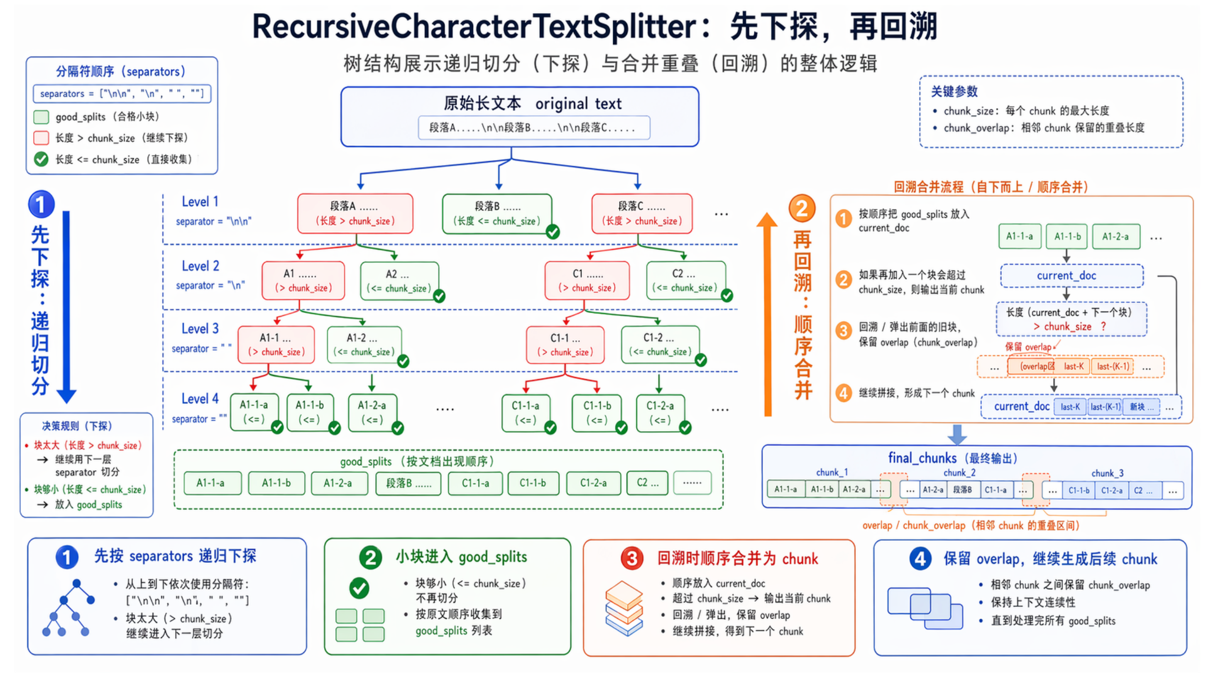

### 4.3 TokenTextSplitter/CharacterTextSplitter: Split by tokens

当我们将文本拆分为块时，除了字符以外，还可以： **按Token的数量分割** （而非字符或单词数），将长文本切分成多个小块。

为什么按token分割？

- 语言模型对 输入长度的限制 是基于Token数（如GPT-4的8k/32k Token上限），直接按字符或单词分割可能导致实际Token数超限。（确保每个文本块不超过模型的Token上限）
- 大语言模型(LLM)通常是以token的数量作为其 计量(或收费) 的依据，所以采用token分割也有助于我们在使用时更方便的控制成本。

TokenTextSplitter使用说明：
- 核心依据：Token数量 + 自然边界。（TokenTextSplitter 严格按照 token 数量进行分割，但同时会优先在自然边界（如句尾）处切断，以尽量保证语义的完整性。）
- 优点：与LLM的Token计数逻辑一致，能尽量保持语义完整。
- 缺点：对非英语或特定领域文本，Token化效果可能不佳。
- 典型场景：需要精确控制Token数输入LLM的场景。

TokenTextSplitter 底层会用到 token 编码器，后者的主要功能是将输入的文本切分为token序列，并将token序列映射为ID序列，本质上是一个 tokenizer 。

举例1:使用TokenTextSplitter

In [8]:
from langchain_text_splitters import TokenTextSplitter

splitter = TokenTextSplitter(
    chunk_size=33,
    chunk_overlap=0,
    encoding_name="cl100k_base" # 使用 OpenAI 的编码器,将文本转换为 token 序列
)

text = "人工智能是一个强大的开发框架。它支持多种语言模型和工具链。人工智能是指通过计算机程序模拟人类智能的一门科学。自20世纪50年代诞生以来，人工智能经历了多次起伏。"

texts = splitter.split_text(text)

print(f"原始文本被分割成了 {len(texts)} 个块:")
for i, chunk in enumerate(texts):
    print(f"块 {i+1}: 长度：{len(chunk)} 内容：{chunk}")
    print("-" * 50)

原始文本被分割成了 3 个块:
块 1: 长度：29 内容：人工智能是一个强大的开发框架。它支持多种语言模型和工具链。
--------------------------------------------------
块 2: 长度：32 内容：人工智能是指通过计算机程序模拟人类智能的一门科学。自20世纪50
--------------------------------------------------
块 3: 长度：19 内容：年代诞生以来，人工智能经历了多次起伏。
--------------------------------------------------


为什么会出现这样的分割？

1、第一块 (29字符) ：内容是一个完整的句子，以句号结尾。TokenTextSplitter识别到这是一个自然的语义边界，即使这里的 token 数量可能尚未达到 33，它也选择在此处切割，以保证第一块语义的完整性。

2、第二块 (32字符) ：内容包含了另一个完整句子 “人工智能是指...一门科学。” 以及下一句的开头“自20世纪50” 。分割器在处理完第一个句子的 token 后，可能 token 数量已经接近 chunk_size ，于是在下一个自然边界（这里是句号）之后继续读取了少量 token（“自20世纪50”），直到非常接近 33token 的限制。

注意：“50” 之后被切断，是因为编码器很可能将“50”识别为一个独立的 token，而“年代”是另一个token。为了保证 token 的完整性，它不会在“50”字符中间切断。

3、第三块 (19字符) ：是第二块中断内容的剩余部分，形成了一个较短的块。这是因为剩余内容本身的token 数量就较少。

特别注意：字符长度不等于 Token 数量。

参数说明

可选编码器位于 openai_public.py 文件的全局变量中，如下所示
```
ENCODING_CONSTRUCTORS = {
    "gpt2": gpt2,
    "r50k_base": r50k_base,
    "p50k_base": p50k_base,
    "p50k_edit": p50k_edit,
    "cl100k_base": cl100k_base,
    "o200k_base": o200k_base,
    "o200k_harmony": o200k_harmony,
}
```

举例2:使用CharacterTextSplitter

In [9]:
splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=18,
    chunk_overlap=0,
    encoding_name="cl100k_base",
    separator="。",
    keep_separator=False
)

text = "人工智能是一个强大的开发框架。它支持多种语言模型和工具链。今天天气很好，想出去踏青。但是又比较懒不想出去，怎么办"

texts = splitter.split_text(text)
print(f"分割后的块数: {len(texts)}")

分割后的块数: 4


### 4.4 SemanticChunker：语义分块

SemanticChunking（语义分块）是LangChain中一种更高级的文本切割方法，它超越了传统的基于字符或固定大小的分块方式，而是根据文本的语义结构进行智能分块，使每个分块保持语义完整性，从而提高检索增强生成（RAG）等应用的效果。

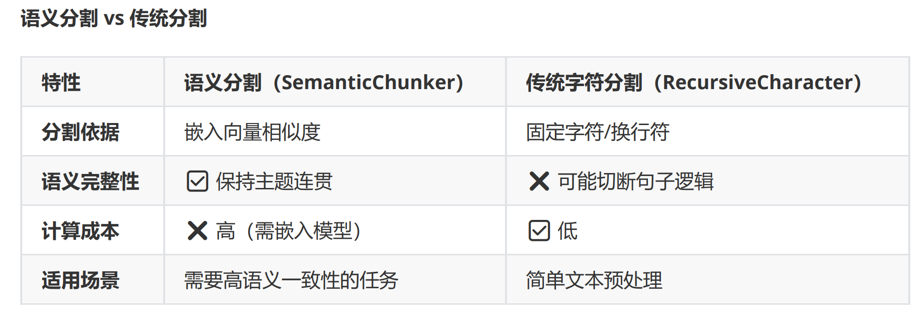

通过将文本转化为 向量（Embedding） ，去计算前后句子的语义差异，当发现前后两句话的语义变化很大（超过设定的阈值）时，就在这里一刀切断。这样能保证切分出来的每一个文本块（Chunk）在含义上是完整、连贯的。

举例：

In [12]:
from langchain_experimental.text_splitter import SemanticChunker
from langchain.embeddings import init_embeddings
import os
from dotenv import load_dotenv

load_dotenv(override=True)

with open("../asset/load/09-ai1.txt", encoding="utf-8") as f:
    text = f.read()

embedding_model = init_embeddings(
    model="qwen3.7-text-embedding-flash",
    provider="openai",
    check_embedding_ctx_length=False,
    # chunk_size=20,
    api_key=os.getenv("ALIYUN_API_KEY"),
    base_url=os.getenv("ALIYUN_BASE_URL")
)

splitter = SemanticChunker(
    embeddings=embedding_model,
    breakpoint_threshold_type="percentile", # 断点阈值类型：字面值["百分位数","标准差", "四分位距", "梯度"] 选其一
    breakpoint_threshold_amount=65.0, # 断点阈值数量 (极低阈值 → 高分割敏感度)
    sentence_split_regex=r"(?<=[。？！])\s+"  # # 句子切分正则:遇到中文的句号、感叹号、问号（。？！）且后面带有空格时，先将其切分为独立的“句子”。
)

docs = splitter.create_documents([text])
print(len(docs))
for doc in docs:
    print(f"🔍 文档: {doc}")

7
🔍 文档: page_content='人工智能综述：发展、应用与未来展望

摘要
人工智能（Artificial Intelligence，AI）作为计算机科学的一个重要分支，近年来取得了突飞猛进的发展。本文综述了人工智能的发展历程、核心技术、应用领域以及未来发展趋势。通过对人工智能的定义、历史背景、主要技术（如机器学习、深度学习、自然语言处理等）的详细介绍，探讨了人工智能在医疗、金融、教育、交通等领域的应用，并分析了人工智能发展过程中面临的挑战与机遇。最后，本文对人工智能的未来发展进行了展望，提出了可能的突破方向。 1. 引言
人工智能是指通过计算机程序模拟人类智能的一门科学。自20世纪50年代诞生以来，人工智能经历了多次起伏，近年来随着计算能力的提升和大数据的普及，人工智能技术取得了显著的进展。人工智能的应用已经渗透到日常生活的方方面面，从智能手机的语音助手到自动驾驶汽车，从医疗诊断到金融分析，人工智能正在改变着人类社会的运行方式。 2. 人工智能的发展历程
2.1 早期发展
人工智能的概念最早可以追溯到20世纪50年代。1956年，达特茅斯会议（Dartmouth Conference）被认为是人工智能研究的正式开端。在随后的几十年里，人工智能研究经历了多次高潮与低谷。早期的研究主要集中在符号逻辑和专家系统上，但由于计算能力的限制和算法的不足，进展缓慢。 2.2 机器学习的兴起
20世纪90年代，随着统计学习方法的引入，机器学习逐渐成为人工智能研究的主流。支持向量机（SVM）、决策树、随机森林等算法在分类和回归任务中取得了良好的效果。这一时期，机器学习开始应用于数据挖掘、模式识别等领域。'
🔍 文档: page_content='2.3 深度学习的突破
2012年，深度学习在图像识别领域取得了突破性进展，标志着人工智能进入了一个新的阶段。深度学习通过多层神经网络模拟人脑的工作方式，能够自动提取特征并进行复杂的模式识别。卷积神经网络（CNN）、循环神经网络（RNN）和长短期记忆网络（LSTM）等深度学习模型在图像处理、自然语言处理、语音识别等领域取得了显著成果。 3. 人工智能的核心技术
3.1 机器学习
机器学习是人工智能的核心技术之一，通过算法使计算机从数据中学习并做出决策。常见的机器学习算法包括监督学习、无监督学习和强化学习。监督学习通过标记数据进行

关于参数的说明：
1. breakpoint_threshold_type （断点阈值类型）
- 作用：定义文本语义边界的检测算法，决定何时分割文本块。
- 可选值及原理：

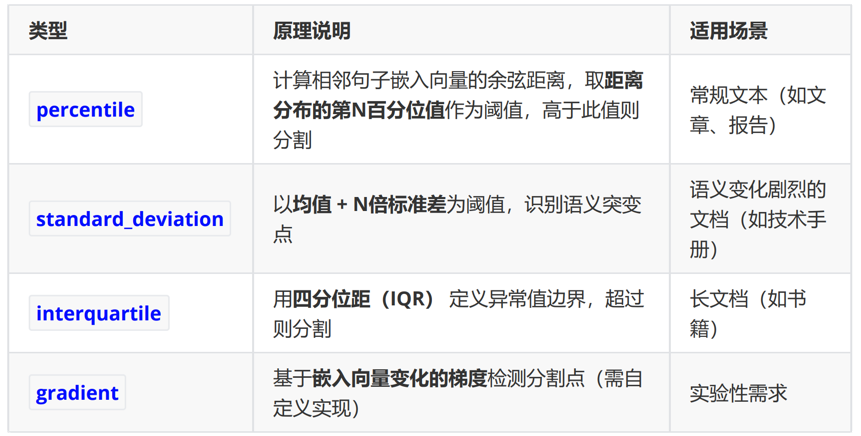

2. breakpoint_threshold_amount （断点阈值量）
- 作用：控制分割的粒度敏感度，值越小分割越细（块越多），值越大分割越粗（块越少）。
- 取值范围与示例：
    - percentile 模式：0.0~100.0，用户代码设 65.0 表示只有当某两个相邻句子的语义差距，超过了全篇 65% 的句子间距时，才进行切分 。默认值是：95.0。
        - 数值越小（比如 20）：切分越敏感，语义稍微有一点点不一样就切开，碎片会很多、很小。
        - 数值越大（比如 95）：切分越迟钝，只有话题发生剧烈转变时才切开，文档块会很大。
    - standard_deviation 模式：浮点数（如 1.5 表示均值+1.5倍标准差）。
    - interquartile 模式：倍数（如 1.5 是IQR标准值）。

3. sentence_split_regex （句子切分的正则表达式）
- 作用：自定义切分文本的正则表达式。如果不传递，默认表达式为 r"(?<=[.?!])\s+" 。
- 代码中 r"(?<=[。？！])\s+" 表示：遇到中文的句号、感叹号、问号（。？！）且后面带有空格时，先将其切分为独立的“句子”。

SemanticChunker 的底层逻辑是先按照正则表达式切分为 chunk 列表，然后计算相邻chunk之间的距离，按照 breakpoint_threshold_type 和 breakpoint_threshold_amount 的规则确定满足规则的切分位置，按照切分位置合并相邻块。

### 4.5 HTMLHeaderTextSplitter

HTMLHeaderTextSplitter是一种专门用于处理HTML文档的文本分割方法，它根据HTML的 标题标签（如`<h1>、<h2>`等） 将文档划分为逻辑分块，同时保留标题的层级结构信息。

In [16]:

from langchain_text_splitters import HTMLHeaderTextSplitter

with open("../asset/load/07-load.html", encoding="utf-8") as f:
    docs = f.read()

# 用于指定要根据哪些HTML标签来分割文本
headers_to_split_on = [
    ("h1", "标题1"),
    ("h2", "标题2"),
    ("h3", "标题3"),
]

splitter = HTMLHeaderTextSplitter(headers_to_split_on=headers_to_split_on)

paragraphs = splitter.split_text(docs)
for para in paragraphs:
    print(para)
    print('-------')

page_content='首发于自然语言处理算法与实践  
切换模式'
-------
page_content='RAG:将检索与生成方式相结合来做生成任务' metadata={'标题1': 'RAG:将检索与生成方式相结合来做生成任务'}
-------
page_content='烛之文' metadata={'标题1': 'RAG:将检索与生成方式相结合来做生成任务'}
-------
page_content='1、前言' metadata={'标题1': 'RAG:将检索与生成方式相结合来做生成任务', '标题2': '1、前言'}
-------
page_content='在上一篇<kNN-NER：利用knn近邻算法来做命名实体识别>提及到文中提出kNN-NER框架是一种检索式增强的方法（retrieval augmented methods），就去查看有关retrieval augmented的paper，了解其核心思想，觉得检索式增强的方法很适合许多业务场景使用，因其以一种简捷的方式将外部知识融于模型中去。今天就分享一篇来自Facebook AI Research的paper<Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks>，论文提出一种检索式增强生成方法，应用于知识密集型的NLP任务（如问答生成），该篇论文被2020年NeurIPS 会议接收。  
文中说到，以BERT之类的大规模预训练模型将很多事实知识信息存入模型中，可以看着是pre-trained parametric类型，尽管以fine-tuned方式在下游任务取得显著的成效，但这类方法仍存在无法精准地获取和操作知识的缺陷。而在上述提及的问题上，传统知识检索的方法能很好的应对，这类方法可以看着是non-parametric memory类型。于是，论文提出检索式增强生成方法（retrieval-augmented generation，RAG），主要思想就是将pre-trained parametric与non-parametric memory结合起来做语言生成任务，将两类模型集成起来提高任务处理效果。' metadata={'标题1': 'RAG:将检索与生成方式相结合来做生成任务', '标题2':

说明：
- 标题下文本内容所属标题的层级信息保存在元数据中。
- 每个分块会自动继承父级标题的上下文，避免信息割裂。

### 4.6 CodeTextSplitter

CodeTextSplitter是一个 专为代码文件 设计的文本分割器（Text Splitter），支持代码的语言包括['cpp', 'go', 'java', 'js', 'php', 'proto', 'python', 'rst', 'ruby', 'rust', 'scala', 'swift', 'markdown', 'latex','html', 'sol']。它能够根据编程语言的语法结构（如函数、类、代码块等）智能地拆分代码，保持代码逻辑的完整性。

与递归文本分割器（如RecursiveCharacterTextSplitter）不同，CodeTextSplitter 针对代码的特性进行了优化， 避免在函数或类的中间截断 。

举例1：支持的语言

In [17]:
from langchain_text_splitters import Language
# 支持分割语言类型
# Full list of supported languages
langs = [e.value for e in Language]
print(langs)

['cpp', 'go', 'java', 'kotlin', 'js', 'ts', 'php', 'proto', 'python', 'r', 'rst', 'ruby', 'rust', 'scala', 'swift', 'markdown', 'latex', 'html', 'sol', 'csharp', 'cobol', 'c', 'lua', 'perl', 'haskell', 'elixir', 'powershell', 'visualbasic6']


In [18]:
# 1.导入相关依赖
from langchain_text_splitters import Language, RecursiveCharacterTextSplitter
from pprint import pprint

# 2.定义要分割的python代码片段
PYTHON_CODE = """
def hello_world():
    print("Hello, World!")

def hello_world1():
    print("Hello, World1!")
"""

python_splitter = RecursiveCharacterTextSplitter.from_language(
    language=Language.PYTHON,
    chunk_size=50,
    chunk_overlap=0
)

# 4.文档切分
python_docs = python_splitter.create_documents(texts=[PYTHON_CODE])
pprint(python_docs)

[Document(metadata={}, page_content='def hello_world():\n    print("Hello, World!")'),
 Document(metadata={}, page_content='def hello_world1():\n    print("Hello, World1!")')]


### 4.7 MarkdownTextSplitter

因为Markdown格式有特定的语法，一般整体内容由 h1、h2、h3 等多级标题组织，所以MarkdownHeaderTextSplitter的切分策略就是根据 标题来分割文本内容 。

In [19]:
from langchain_text_splitters import MarkdownTextSplitter

markdown_text = """
# 一级标题\n
这是一级标题下的内容\n\n
## 二级标题\n
- 二级下列表项1\n
- 二级下列表项2\n
"""

# 关键步骤：直接修改实例属性
splitter = MarkdownTextSplitter(chunk_size=30, chunk_overlap=0)
splitter._is_separator_regex = True # 强制将分隔符视为正则表达式

# 执行分割
docs = splitter.create_documents(texts = [markdown_text])
for i, doc in enumerate(docs):
    print(f"\n🔍 分块 {i + 1}:")
    print(doc.page_content)


🔍 分块 1:
# 一级标题

这是一级标题下的内容

🔍 分块 2:
## 二级标题

- 二级下列表项1

- 二级下列表项2
